# Question 3: Retail Customer Segmentation
**Task:** Unsupervised Machine Learning – Clustering  
**Input Features:** `purchase_frequency`, `spending_score`, `annual_income`, `avg_order_value`  
**Goal:** Group customers into natural segments without predefined categories.  

### Marks Rubric (40 Marks):
1. **Section 1: EDA [10 Marks]** — Dataset creation, inspection, and scale disparity check
2. **Section 2: Technique Implementation [10 Marks]** — Standardization & Baseline K-Means Clustering
3. **Section 3: Evaluate Model [10 Marks]** — Elbow Method (Inertia), Silhouette Score, and Cluster Scatter Plot
4. **Section 4: Modify Technique Based on Requirement [10 Marks]** — Agglomerative Hierarchical Clustering with Dendrogram (Ward Linkage)

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams['figure.figsize'] = (8, 4)
print("Libraries imported successfully!")

Libraries imported successfully!


## Section 1: Exploratory Data Analysis (EDA) [10 Marks]

In [2]:
# 1.1 Simple Exam-Friendly Dataset Generation (400 samples)
np.random.seed(42)
n = 400

purchase_frequency = np.random.randint(2, 50, n)       # Purchases per year
spending_score = np.random.uniform(5, 100, n)          # Spending score 1-100
annual_income = np.random.uniform(20, 120, n)          # Income in thousands ($k)
avg_order_value = np.random.uniform(15, 250, n)        # Average order value ($)

df = pd.DataFrame({
    'purchase_frequency': purchase_frequency,
    'spending_score': np.round(spending_score, 1),
    'annual_income': np.round(annual_income, 1),
    'avg_order_value': np.round(avg_order_value, 1)
})

print("Dataset created! Shape:", df.shape)
df.head()

Dataset created! Shape: (400, 4)


,purchase_frequency,spending_score,annual_income,avg_order_value
0,40,71.7,116.9,66.3
1,30,80.6,106.6,238.2
2,16,89.6,101.7,199.8
3,44,37.1,45.8,36.0
4,9,40.7,37.1,113.1


In [3]:
# 1.2 Inspection & Scale Disparity
print("=== Dataset Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Summary Statistics (Notice different scales across features) ===")
display(df.describe().round(2))

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   purchase_frequency  400 non-null    int64  
 1   spending_score      400 non-null    float64
 2   annual_income       400 non-null    float64
 3   avg_order_value     400 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 12.6 KB

=== Missing Values ===
purchase_frequency    0
spending_score        0
annual_income         0
avg_order_value       0
dtype: int64

=== Summary Statistics (Notice different scales across features) ===


,purchase_frequency,spending_score,annual_income,avg_order_value
count,400.00,400.00,400.00,400.00
mean,26.00,51.29,69.49,136.62
std,13.83,28.21,28.97,69.96
min,2.00,6.00,20.50,16.20
25%,15.00,25.42,44.12,70.22
50%,27.00,51.75,69.55,142.20
75%,37.00,76.03,94.18,196.98
max,49.00,100.00,119.80,249.90


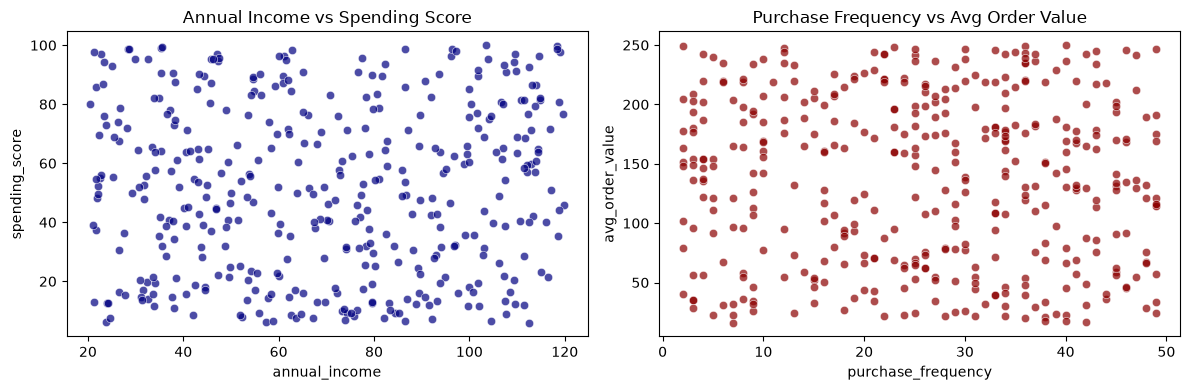

In [4]:
# 1.3 EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Scatter Plot: Annual Income vs Spending Score
sns.scatterplot(x='annual_income', y='spending_score', data=df, ax=axes[0], color='navy', alpha=0.7)
axes[0].set_title("Annual Income vs Spending Score")

# Scatter Plot: Purchase Frequency vs Avg Order Value
sns.scatterplot(x='purchase_frequency', y='avg_order_value', data=df, ax=axes[1], color='darkred', alpha=0.7)
axes[1].set_title("Purchase Frequency vs Avg Order Value")

plt.tight_layout()
plt.show()

## Section 2: Unsupervised Technique Implementation [10 Marks]

In [5]:
# 2.1 Feature Standardization (Crucial for distance-based clustering)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 2.2 Baseline Model: K-Means Clustering (k=3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

print("K-Means (k=3) fitted!")
print("Cluster Membership Counts:\n", df['cluster_kmeans'].value_counts())

K-Means (k=3) fitted!
Cluster Membership Counts:
 cluster_kmeans
0    143
2    131
1    126
Name: count, dtype: int64


## Section 3: Model Evaluation [10 Marks]

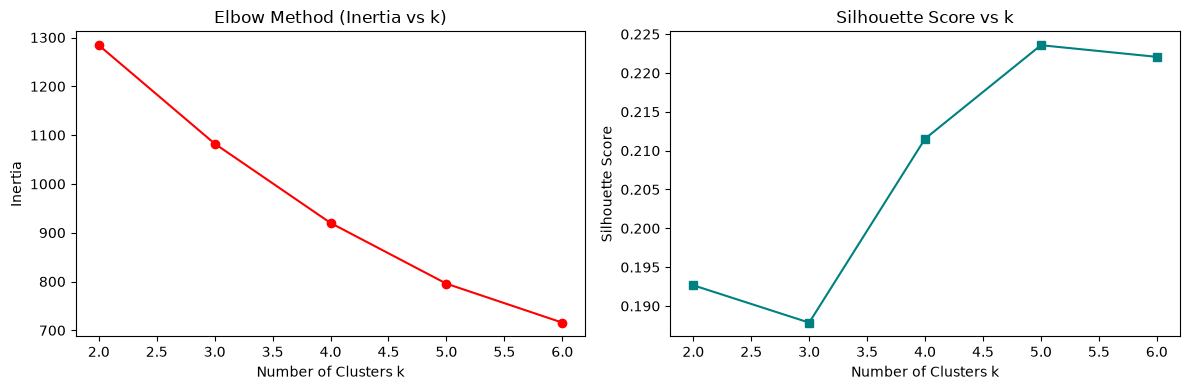

Silhouette Score for k=3: 0.1879


In [6]:
# 3.1 Elbow Method (Inertia) & Silhouette Score across k = 2 to 6
k_range = range(2, 7)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_range, inertias, marker='o', color='red')
axes[0].set_title("Elbow Method (Inertia vs k)")
axes[0].set_xlabel("Number of Clusters k")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, sil_scores, marker='s', color='teal')
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("Number of Clusters k")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print(f"Silhouette Score for k=3: {silhouette_score(X_scaled, df['cluster_kmeans']):.4f}")

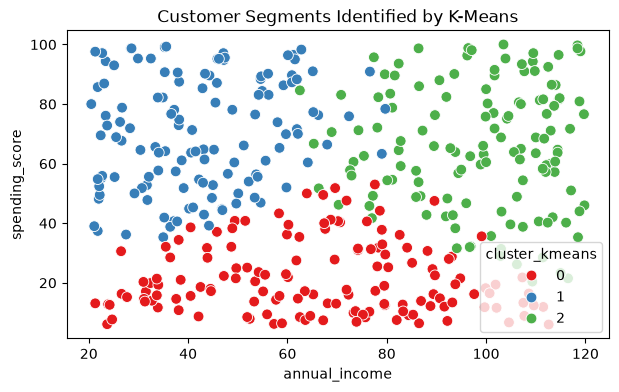

,purchase_frequency,spending_score,annual_income,avg_order_value
cluster_kmeans,,,,
0,27.45,21.49,66.42,124.94
1,26.33,70.07,42.60,127.38
2,24.11,65.76,98.72,158.25


In [7]:
# 3.2 Visualizing K-Means Clusters
plt.figure(figsize=(7, 4))
sns.scatterplot(x='annual_income', y='spending_score', hue='cluster_kmeans', data=df, palette='Set1', s=60)
plt.title("Customer Segments Identified by K-Means")
plt.show()

# Mean profile of each cluster
display(df.groupby('cluster_kmeans').mean().round(2))

## Section 4: Modify Technique Based on Requirement [10 Marks]
**Modifications Applied (from Lab 9):**
1. **Agglomerative Hierarchical Clustering:** To understand hierarchical taxonomy and cluster relationships without fixing $k$ upfront.
2. **Dendrogram Visualization:** Using Ward linkage to visually decide the cut-off height.

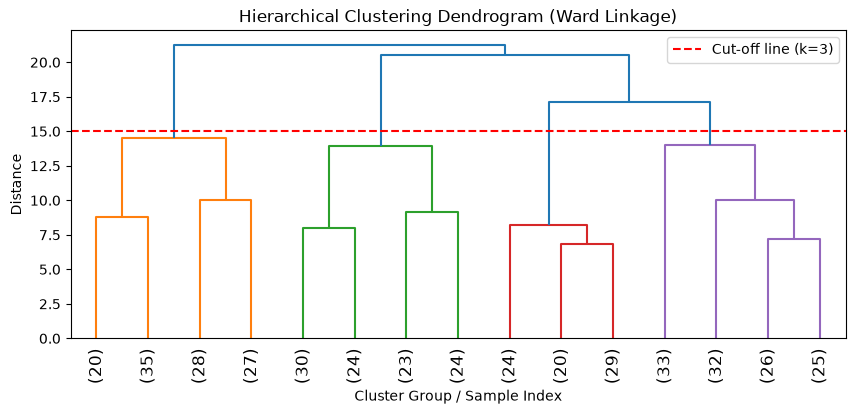

In [8]:
# 4.1 Hierarchical Clustering Dendrogram (Ward Linkage)
plt.figure(figsize=(10, 4))
linkage_matrix = linkage(X_scaled, method='ward')
dendrogram(linkage_matrix, truncate_mode='lastp', p=15, leaf_rotation=90.)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Cluster Group / Sample Index")
plt.ylabel("Distance")
plt.axhline(15, color='red', linestyle='--', label='Cut-off line (k=3)')
plt.legend()
plt.show()

# Fit Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['cluster_hierarchical'] = agg.fit_predict(X_scaled)

In [9]:
# 4.2 Comparison Table: K-Means vs Hierarchical
sil_km = silhouette_score(X_scaled, df['cluster_kmeans'])
sil_agg = silhouette_score(X_scaled, df['cluster_hierarchical'])

comparison_df = pd.DataFrame([
    {'Algorithm': 'K-Means (k=3)', 'Silhouette Score': round(sil_km, 4)},
    {'Algorithm': 'Agglomerative Hierarchical (Ward)', 'Silhouette Score': round(sil_agg, 4)}
])
print("=== Clustering Comparison Table ===")
display(comparison_df)

=== Clustering Comparison Table ===


,Algorithm,Silhouette Score
0,K-Means (k=3),0.1879
1,Agglomerative Hierarchical (Ward),0.1519
